# Emission maps from PGD_aer.fa
Plots the `X001E_*` emission fields (anthro `_em`, biomass burning `_bb`) on the ALPX3 grid.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import epygram

epygram.init_env()

PGD_FILE = 'PGD_aer.fa'
FIELDS = ['X001E_BC_em', 'X001E_OC_em', 'X001E_SO2_em',
          'X001E_BC_bb', 'X001E_OC_bb', 'X001E_SO2_bb']
# the SO2 anthro field may still be called SO2_e (see dict_var_to_treat.py)


In [2]:
r = epygram.formats.resource(PGD_FILE, 'r')
available = set(r.listfields())
fields = [f for f in FIELDS if f in available] + [f for f in ['X001E_SO2_e'] if f in available and 'X001E_SO2_em' not in available]
print(fields)

lon, lat = r.readfield(fields[0]).geometry.get_lonlat_grid()
data = {f: np.ma.getdata(r.readfield(f).getdata()).astype(float) for f in fields}


['X001E_BC_em', 'X001E_OC_em', 'X001E_BC_bb', 'X001E_OC_bb', 'X001E_SO2_bb', 'X001E_SO2_e']


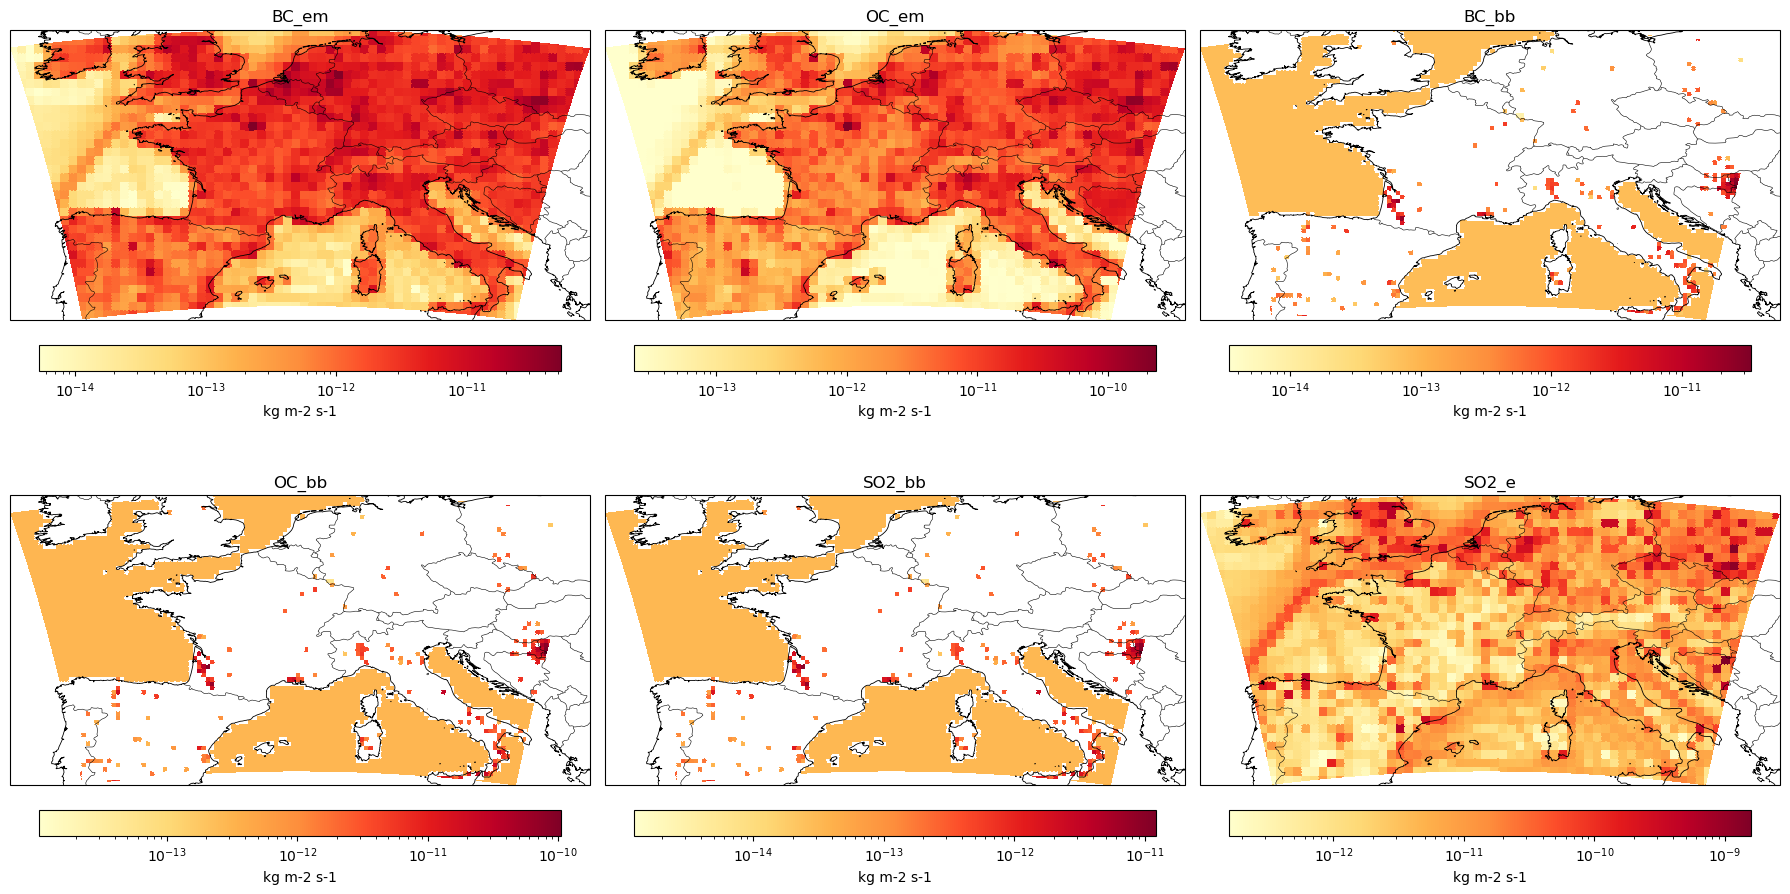

In [3]:
ncol = 3
nrow = -(-len(fields) // ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(6 * ncol, 5 * nrow),
                         subplot_kw={'projection': ccrs.PlateCarree()}, squeeze=False)
for ax, f in zip(axes.flat, fields):
    d = np.where(data[f] > 0, data[f], np.nan)   # zeros (no fire) are blanked for the log scale
    vmax = np.nanmax(d)
    m = ax.pcolormesh(lon, lat, d, norm=LogNorm(vmin=vmax * 1e-4, vmax=vmax),
                      cmap='YlOrRd', transform=ccrs.PlateCarree(), shading='auto')
    ax.coastlines(resolution='10m', linewidth=0.6)
    ax.add_feature(cfeature.BORDERS, linewidth=0.4)
    ax.set_title(f.replace('X001E_', ''))
    plt.colorbar(m, ax=ax, orientation='horizontal', pad=0.05, shrink=0.9, label='kg m-2 s-1')
for ax in axes.flat[len(fields):]:
    ax.axis('off')
plt.tight_layout()
plt.show()


## Where is the emission? Totals and hotspots

In [4]:
for f in fields:
    d = data[f]
    i = np.unravel_index(np.argmax(d), d.shape)
    print('%-14s max %.3g at lon %.2f lat %.2f | non-zero points: %.1f %%' %
          (f.replace('X001E_', ''), d[i], lon[i], lat[i], 100 * (d > 0).mean()))


BC_em          max 5.28e-11 at lon 2.02 lat 48.51 | non-zero points: 100.0 %
OC_em          max 2.34e-10 at lon 2.02 lat 48.51 | non-zero points: 100.0 %
BC_bb          max 3.4e-11 at lon 19.28 lat 45.25 | non-zero points: 35.3 %
OC_bb          max 1.05e-10 at lon 19.28 lat 45.25 | non-zero points: 35.3 %
SO2_bb         max 1.22e-11 at lon 19.28 lat 45.25 | non-zero points: 35.3 %
SO2_e          max 1.58e-09 at lon 18.51 lat 44.50 | non-zero points: 100.0 %
